In [1]:
import numpy as np
import pandas as pd
from  pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns   
from scipy.stats import chi2_contingency
from scipy .stats import f_oneway
import sys

sys.path.append(str(Path.cwd().parents[3]))
from helpers import chi2_test, anova_test

dataDirectoty = Path.cwd().parents[4] / 'data'

trainData = pd.read_csv(dataDirectoty / 'train.csv').copy()

First lets check if it's worth it to make this imputer, we will check if Embarked and Survived features are independent or not.

Frequencies:  Embarked
S      0.722783
C      0.188552
Q      0.086420
NaN    0.002245
Name: proportion, dtype: float64
Cardinality(Not NaN):  3
H0 = Embarked and survived are independent
H1 = Embarked and survived are dependent


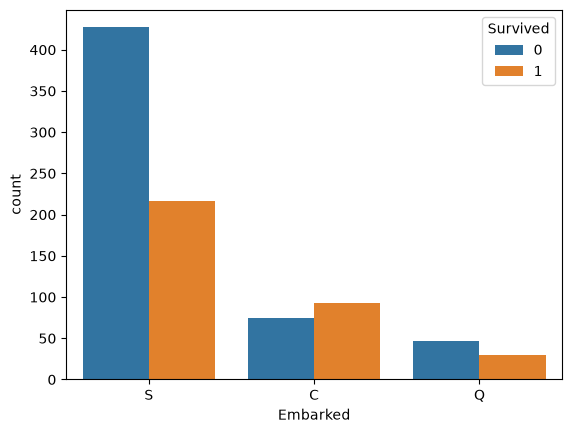

In [2]:
print("Frequencies: ", trainData['Embarked'].value_counts(normalize=True, dropna=False))
print("Cardinality(Not NaN): ", trainData['Embarked'].nunique())

print("H0 = Embarked and survived are independent")
print("H1 = Embarked and survived are dependent")



sns.countplot(data=trainData, x="Embarked", hue="Survived")
plt.show()

### Embarking against categotical features

In [3]:
categorical_columns_to_compare = ['Pclass', 'Sex']
print("Chi² tests")
print("--------------------")
for feature in categorical_columns_to_compare:
    chi2_test(trainData, 'Embarked', feature, 0.05)
    print("--------------------")


Chi² tests
--------------------
Chi² test:
	H0: Embarked and Pclass are independent
	H1: Embarked and Pclass are dependent
	We reject H0
	P value: 8.435267819894384e-26
--------------------
Chi² test:
	H0: Embarked and Sex are independent
	H1: Embarked and Sex are dependent
	We reject H0
	P value: 0.0012585245232290144
--------------------


### Embarking against numerical features

In [5]:
numerical_columns_to_compare = ['Age', 'Fare']
print("ANOVA tests")
print("--------------------")
for feature in numerical_columns_to_compare:
    anova_test(trainData, 'Embarked', feature, 0.05)
    print("--------------------")

ANOVA tests
--------------------
ANOVA test:
	H0: Embarked and Age are independent
	H1: Embarked and Age are dependent
We do not reject H0
	F: 0.6366398124910263, p value: 0.5293693792569866
--------------------
ANOVA test:
	H0: Embarked and Fare are independent
	H1: Embarked and Fare are dependent
	We reject H0
	F: 38.140305200112664, p value: 1.2896450252637108e-16
--------------------
